# 09. Control flow: `where`, `max`, `clip` and lookup tables

Engineering models are full of switches: a friction factor that depends on the flow regime, an efficiency that saturates,
a property read from a table, a tariff with tiers. In Python these are one-liners: `jnp.where`, `jnp.maximum`, `jnp.clip`, `jnp.interp`.
In an algebraic modeling language each one is a *disjunction*: it needs binary variables or a GDP (generalized disjunctive programming) block,
and you must supply bounds so the big-M constants are finite and tight.

For a global solver a switch is hard for two reasons. First, the function is only piecewise smooth, so a single convex
underestimator over a box that contains the switch has to cover both pieces. Second, an equation-based solver cannot
branch on "which piece" unless the model tells it there is a choice, which is what the binaries do. jaxglobal works
from the code instead: when a box straddles the switch it bounds both branches and takes their hull, and branching on
the continuous variables eventually separates the pieces.

This notebook writes two such models both ways:

* **A. Pipe and pump sizing** with a laminar/turbulent friction-factor switch (`where`) and a saturating pump efficiency (`clip`).
* **B. Steam-heated exchanger** with the saturation temperature, latent heat and utility price read from tables as a function of steam pressure (`interp`, `maximum`).

The Pyomo versions [hart2011pyomo, bynum2021pyomo] are written carefully: `pyomo.gdp` disjunctions with the big-M transformation for the regime switch,
and `pyomo.environ.Piecewise` (incremental formulation) for the tables.
They are solved with SCIP [vigerske2018scip], Couenne [belotti2009branching] and BARON [tawarmalani2005polyhedral] (through GAMS),
all with relative gap 1e-4; where GAMS is not installed the BARON row reads "not run". jaxglobal handles the same models as plain code.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo
import pyomo.gdp as gdp

import jaxglobal
from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
SOLVERS = ("scip", "couenne", "baron")
COLOR = {"scip": BLUE, "couenne": AQUA, "baron": YELLOW, "jaxglobal": ORANGE}
MARKER = {"scip": "o", "couenne": "s", "baron": "D", "jaxglobal": "*"}


def n_binary(m):
    return sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary())


# `solve_jax` keeps only a summary of each jaxglobal run. Record the full Result as it passes through,
# so the bound history can be plotted below without solving again.
_minimize, JAX_RESULTS = jaxglobal.minimize, []


def _recording_minimize(*args, **kw):
    r = _minimize(*args, **kw)
    JAX_RESULTS.append(r)
    return r


jaxglobal.minimize = _recording_minimize

## A. Pipe sizing with a flow-regime switch

A viscous oil (density $\rho$ = 900 kg/m³, viscosity $\mu$ = 0.05 Pa s) is pumped through a pipe of length $L$ = 200 m.
The decision variables are the volumetric flow $Q \in [10^{-4}, 10^{-2}]$ m³/s and the diameter $D \in [0.02, 0.3]$ m.
The yearly profit is a revenue linear in $Q$, minus the cost of pumping energy, minus a pipe cost proportional to $D^{1.5} L$.
The numbers are illustrative.

* Mean velocity $v = 4Q/(\pi D^2)$ and Reynolds number $Re = \rho v D/\mu = 4\rho Q/(\pi \mu D)$.
* Darcy friction factor. Laminar: $f = 64/Re$ (Hagen-Poiseuille). Turbulent: the explicit Swamee-Jain correlation [swamee1976explicit]
  to the Colebrook equation [colebrook1939turbulent], with wall roughness $\varepsilon$,

  $$ f(Re, D) = \begin{cases} \dfrac{64}{Re}, & Re < 2300,\\[2ex]
     \dfrac{0.25}{\Big[\log_{10}\!\Big(\dfrac{\varepsilon}{3.7D} + \dfrac{5.74}{Re^{0.9}}\Big)\Big]^2}, & Re \ge 2300. \end{cases} $$

  The switch at $Re=2300$ is a common textbook rule (the Moody chart [moody1944friction] leaves 2300-4000 as a transition zone,
  and Swamee and Jain fitted their formula for $Re \ge 5000$). The resulting $f$ jumps at $Re = 2300$: a modeling choice, not physics.
* Pressure drop (Darcy-Weisbach) $\Delta P = f\,(L/D)\,\rho v^2/2$.
* Pump efficiency $\eta = \mathrm{clip}(0.2 + 600Q,\ 0.35,\ 0.75)$ (an illustrative curve) and shaft power $W = \Delta P\, Q/\eta$.

With revenue price $p$, energy cost $c_E$ and pipe-cost scale $c_D$ the problem is

$$ \min_{Q,\,D}\ \ -p\,Q \;+\; c_E\,\frac{\Delta P(Q,D)\,Q}{\eta(Q)} \;+\; c_D\,\frac{L}{100}\,D^{1.5}
   \qquad \text{s.t.}\quad 10^{-4} \le Q \le 10^{-2},\quad 0.02 \le D \le 0.3 . $$

The switch changes how the pumping cost scales. In laminar flow $f = 64/Re$ cancels the velocity dependence and
$\Delta P\,Q = 128\,\mu L Q^2/(\pi D^4)$; in turbulent flow $f$ varies only slowly with $Re$, so $\Delta P\,Q \propto f\,Q^3/D^5$.
Since $Re \propto Q/D$, a narrow pipe pushes the flow into the turbulent regime and pays twice, through the jump in $f$ and
through the steeper scaling. The objective is nonconvex on either side and discontinuous across the line $Re = 2300$.

### The two switches, drawn

The left panel draws $f(Re)$ for three diameters (the turbulent branch depends on $\varepsilon/D$). Solid lines are the branch
the model uses, dashed lines the branch it discards. The right panel is the efficiency curve with the four breakpoints that the
Pyomo `Piecewise` block below uses; `clip` is piecewise linear, so those four points represent it exactly.

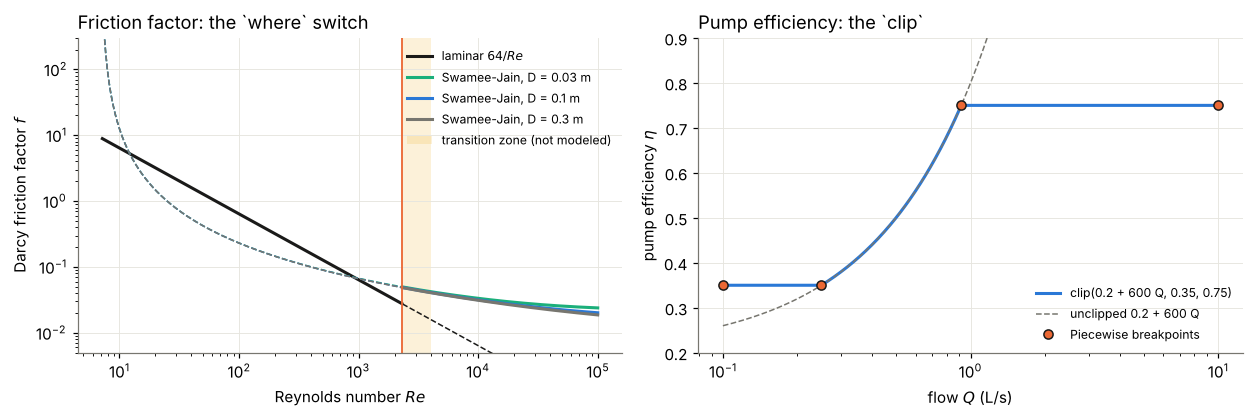

D = 0.03 m: f jumps from 0.0278 (laminar) to 0.0500 (turbulent) at Re = 2300; Swamee-Jain pole at Re = 6.973
D =  0.1 m: f jumps from 0.0278 (laminar) to 0.0491 (turbulent) at Re = 2300; Swamee-Jain pole at Re = 6.971
D =  0.3 m: f jumps from 0.0278 (laminar) to 0.0488 (turbulent) at Re = 2300; Swamee-Jain pole at Re = 6.970


In [2]:
RHO, MU, LEN, EPS = 900.0, 0.05, 200.0, 4.5e-5  # kg/m3, Pa s, m, m (commercial steel roughness)
PRICE, E_COST, C_PIPE = 4e5, 0.8, 1.2e4  # $/(m3/s)/yr, $/W/yr, pipe cost scale
QLO, QHI, DLO, DHI = 1e-4, 1e-2, 0.02, 0.3


def sj(Re, D):  # Swamee-Jain, numpy version for plotting
    return 0.25 / np.log10(EPS / (3.7 * D) + 5.74 / Re**0.9) ** 2


Re_plot = np.geomspace(7.2, 1e5, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9))
lam_side = Re_plot < 2300
ax1.loglog(Re_plot[lam_side], 64 / Re_plot[lam_side], color=INK, lw=2, label="laminar $64/Re$")
ax1.loglog(Re_plot[~lam_side], 64 / Re_plot[~lam_side], color=INK, lw=1, ls="--")
for D, c in [(0.03, AQUA), (0.1, BLUE), (0.3, MUTED)]:
    ax1.loglog(Re_plot[~lam_side], sj(Re_plot[~lam_side], D), color=c, lw=2, label=f"Swamee-Jain, D = {D} m")
    ax1.loglog(Re_plot[lam_side], sj(Re_plot[lam_side], D), color=c, lw=1, ls="--")
ax1.axvspan(2300, 4000, color=YELLOW, alpha=0.15, lw=0, label="transition zone (not modeled)")
ax1.axvline(2300, color=ORANGE, lw=1.2)
ax1.set_xlabel("Reynolds number $Re$")
ax1.set_ylabel("Darcy friction factor $f$")
ax1.set_ylim(5e-3, 300)
ax1.set_title("Friction factor: the `where` switch", loc="left")
ax1.legend(frameon=False, fontsize=8)

Qp = np.geomspace(QLO, QHI, 400)
ax2.plot(Qp * 1e3, np.clip(0.2 + 600 * Qp, 0.35, 0.75), color=BLUE, lw=2, label="clip(0.2 + 600 Q, 0.35, 0.75)")
ax2.plot(Qp * 1e3, 0.2 + 600 * Qp, color=MUTED, lw=1, ls="--", label="unclipped 0.2 + 600 Q")
pw_pts = [QLO, 2.5e-4, 0.55 / 600, QHI]
ax2.plot(np.array(pw_pts) * 1e3, [0.35, 0.35, 0.75, 0.75], "o", color=ORANGE, mec=INK, label="Piecewise breakpoints")
ax2.set_ylim(0.2, 0.9)
ax2.set_xscale("log")
ax2.set_xlabel("flow $Q$ (L/s)")
ax2.set_ylabel(r"pump efficiency $\eta$")
ax2.set_title("Pump efficiency: the `clip`", loc="left")
ax2.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
for D in (0.03, 0.1, 0.3):
    print(f"D = {D:4} m: f jumps from {64 / 2300:.4f} (laminar) to {sj(2300.0, D):.4f} (turbulent) at Re = 2300; "
          f"Swamee-Jain pole at Re = {(5.74 / (1 - EPS / (3.7 * D))) ** (1 / 0.9):.3f}")

At $Re = 2300$ the turbulent correlation gives a friction factor well above the laminar one, so crossing the line from the
laminar side raises the pressure drop at once. Note also how the discarded turbulent branch (dashed) shoots up at the
left edge: as $Re$ falls the argument of the logarithm approaches 1, and $f$ has a pole there (printed below). A `where` evaluates both branches, so this
matters for the bounds, as we will see.

### Pyomo

The regime switch becomes a two-term `Disjunction` with Boolean indicators $Y_{\rm lam}$, $Y_{\rm turb}$, exactly one of which is true:

$$ \begin{bmatrix} Y_{\rm lam} \\ Re \le 2300 \\ f\,Re = 64 \end{bmatrix}
   \ \veebar\
   \begin{bmatrix} Y_{\rm turb} \\ Re \ge 2300 \\ f\,\Big[\log_{10}\!\Big(\dfrac{\varepsilon}{3.7D} + \dfrac{5.74}{Re^{0.9}}\Big)\Big]^2 = 0.25 \end{bmatrix} $$

The big-M transformation replaces $Y$ by binaries $y_{\rm lam} + y_{\rm turb} = 1$ and relaxes each disjunct constraint
$g(x) \le 0$ when its disjunct is off (an equality becomes two such inequalities):

$$ g(x) \le M_g\,(1 - y), \qquad M_g \ge \max_{x \in \text{bounds}} g(x). $$

Pyomo computes each $M_g$ by interval arithmetic on $g$ over the variable bounds, so every variable in a disjunct needs finite
bounds, and the looser they are, the larger $M$ and the weaker the continuous relaxation [kronqvist2025psplit].
The Reynolds number is bounded by hand from the box,
$Re \in [4\rho Q^L/(\pi\mu D^U),\ 4\rho Q^U/(\pi\mu D^L)]$, and $f \le 64/Re^L$.
One more manual step: $Re$, $\Delta P$ and the power $W$ become variables with defining equations
($Re\,\pi\mu D = 4\rho Q$, $W\eta = \Delta P\,Q$), because disjunct constraints are written on variables.

The efficiency curve is a `Piecewise` block in the incremental (`INC`) formulation. With breakpoints $q_0 < \dots < q_n$
and values $e_0, \dots, e_n$ it introduces fill fractions $\delta_i \in [0,1]$ and binaries $z_i$:

$$ Q = q_0 + \sum_{i=1}^{n} \delta_i\,(q_i - q_{i-1}), \qquad
   \eta = e_0 + \sum_{i=1}^{n} \delta_i\,(e_i - e_{i-1}), \qquad
   \delta_{i+1} \le z_i \le \delta_i \quad (i = 1, \dots, n-1). $$

The binaries force the segments to fill in order. Four breakpoints give three segments and two binaries, so the model has
four binaries in all (two indicators, two for the efficiency).

In [3]:
def pipe_pyomo():
    Re_lo = 4 * RHO * QLO / (np.pi * MU * DHI)
    Re_hi = 4 * RHO * QHI / (np.pi * MU * DLO)
    m = pyo.ConcreteModel()
    m.Q = pyo.Var(bounds=(QLO, QHI), initialize=5e-3)
    m.D = pyo.Var(bounds=(DLO, DHI), initialize=0.1)
    m.Re = pyo.Var(bounds=(Re_lo, Re_hi), initialize=1000)
    m.f = pyo.Var(bounds=(0.005, 64 / Re_lo), initialize=0.03)
    m.eta = pyo.Var(bounds=(0.35, 0.75), initialize=0.5)
    m.dP = pyo.Var(bounds=(0, 1e9), initialize=1e4)
    m.power = pyo.Var(bounds=(0, 1e7), initialize=1e3)
    m.reynolds = pyo.Constraint(expr=m.Re * np.pi * MU * m.D == 4 * RHO * m.Q)
    m.lam = gdp.Disjunct()
    m.lam.regime = pyo.Constraint(expr=m.Re <= 2300)
    m.lam.hp = pyo.Constraint(expr=m.f * m.Re == 64)
    m.turb = gdp.Disjunct()
    m.turb.regime = pyo.Constraint(expr=m.Re >= 2300)
    m.turb.sj = pyo.Constraint(expr=m.f * pyo.log10(EPS / (3.7 * m.D) + 5.74 / m.Re**0.9) ** 2 == 0.25)
    m.flow_regime = gdp.Disjunction(expr=[m.lam, m.turb])
    m.pressure = pyo.Constraint(expr=m.dP == m.f * (LEN / m.D) * RHO / 2 * (4 * m.Q / (np.pi * m.D**2)) ** 2)
    m.eta_curve = pyo.Piecewise(
        m.eta, m.Q, pw_pts=[QLO, 2.5e-4, 0.55 / 600, QHI], f_rule=[0.35, 0.35, 0.75, 0.75],
        pw_constr_type="EQ", pw_repn="INC",
    )  # fmt: skip
    m.pump = pyo.Constraint(expr=m.power * m.eta == m.dP * m.Q)
    m.obj = pyo.Objective(expr=-PRICE * m.Q + E_COST * m.power + C_PIPE * m.D**1.5 * LEN / 100)
    pyo.TransformationFactory("gdp.bigm").apply_to(m)
    return m

### jaxglobal

The same physics, written the way you would write it for a numerical code. The regime test is `jnp.where`, the efficiency is `jnp.clip`.
$Re$, $f$, $\Delta P$ and the power are ordinary local variables.

In [4]:
def friction(Re, D):
    laminar = 64.0 / Re
    turbulent = 0.25 / jnp.log10(EPS / (3.7 * D) + 5.74 / Re**0.9) ** 2
    return jnp.where(Re < 2300.0, laminar, turbulent)


def pipe(x):
    Q, D = x[0], x[1]
    v = 4 * Q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    dP = friction(Re, D) * (LEN / D) * RHO * v**2 / 2
    eta = jnp.clip(0.2 + 600.0 * Q, 0.35, 0.75)
    return -PRICE * Q + E_COST * dP * Q / eta + C_PIPE * D**1.5 * LEN / 100

### Results

Each Pyomo solver gets its own fresh copy of the model; we keep the copies so the solution each one found can be read back.
The columns are the objective of the returned point, the solver's proven lower bound (NaN where the solver does not report
one through Pyomo), the wall time and the status.

In [5]:
m = pipe_pyomo()
size = model_size(m)
print(f"Pyomo (after GDP transformation): {size[0]} variables ({n_binary(m)} binary), {size[1]} constraints")
print("binaries:", ", ".join(v.name for v in m.component_data_objects(pyo.Var) if v.is_binary()))
models_a = {s: pipe_pyomo() for s in SOLVERS}
rows = [solve_pyomo(models_a[s], s) for s in SOLVERS]
rows.append(solve_jax(pipe, [QLO, DLO], [QHI, DHI]))
res_a = JAX_RESULTS[-1]
table(rows)

Pyomo (after GDP transformation): 14 variables (4 binary), 16 constraints
binaries: eta_curve.INC_bin_y[1], eta_curve.INC_bin_y[2], lam.binary_indicator_var, turb.binary_indicator_var


,solver,obj,bound,time,status
0,scip,-2828.741932,-2828.954308,0.59,optimal
1,couenne,-2828.738593,NaN,0.94,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,-2828.730777,-2828.926933,8.07,optimal


To check the answer independently, evaluate the jaxglobal function on a 400 x 400 grid (a cheap vectorized evaluation, not a certificate), and look at the regime at the optimum.

In [6]:
Qg, Dg = jnp.meshgrid(jnp.linspace(QLO, QHI, 400), jnp.linspace(DLO, DHI, 400))
grid = jax.vmap(jax.vmap(lambda q, d: pipe(jnp.array([q, d]))))(Qg, Dg)
xj = rows[-1]["x"]
Re_opt = RHO * 4 * xj[0] / (np.pi * MU * xj[1])
print(f"grid minimum {float(grid.min()):.1f}  (coarse; jaxglobal {rows[-1]['obj']:.1f})")
print(f"jaxglobal optimum: Q = {xj[0]:.5f} m3/s, D = {xj[1]:.4f} m, Re = {Re_opt:.0f} "
      f"({'laminar' if Re_opt < 2300 else 'turbulent'} side of the switch)")  # fmt: skip
pyomo_xa = {s: (pyo.value(models_a[s].Q), pyo.value(models_a[s].D)) for s, r in zip(SOLVERS, rows) if np.isfinite(r["obj"])}
for s, (q, d) in pyomo_xa.items():
    print(f"{s:>9}: Q = {q:.5f} m3/s, D = {d:.4f} m, Re = {4 * RHO * q / (np.pi * MU * d):.0f}")

grid minimum -2828.7  (coarse; jaxglobal -2828.7)
jaxglobal optimum: Q = 0.01000 m3/s, D = 0.1082 m, Re = 2119 (laminar side of the switch)
     scip: Q = 0.01000 m3/s, D = 0.1080 m, Re = 2122
  couenne: Q = 0.01000 m3/s, D = 0.1080 m, Re = 2122


In [7]:
lp, lj = loc(pipe_pyomo), loc(friction, pipe)
save_results("09", "A: pipe (where, clip)", lp, lj, size, rows,
             note=f"{n_binary(m)} binaries after GDP/Piecewise")  # fmt: skip
print(f"lines of model code: Pyomo {lp}, jaxglobal {lj}")
loc_a, bin_a = (lp, lj), n_binary(m)

lines of model code: Pyomo 28, jaxglobal 11


### Where the optimum sits

The left panel shows the objective over the whole box on a log scale (it spans many orders of magnitude because the
pumping cost grows like $D^{-4}$ to $D^{-5}$). The orange line is $Re = 2300$, i.e. $D = 4\rho Q/(2300\,\pi\mu)$:
above it the flow is laminar. The right panel is a cut along the upper flow bound $Q = Q^U$, where all solvers end up,
with both friction branches drawn; the model follows the solid curve and jumps where the regime changes.

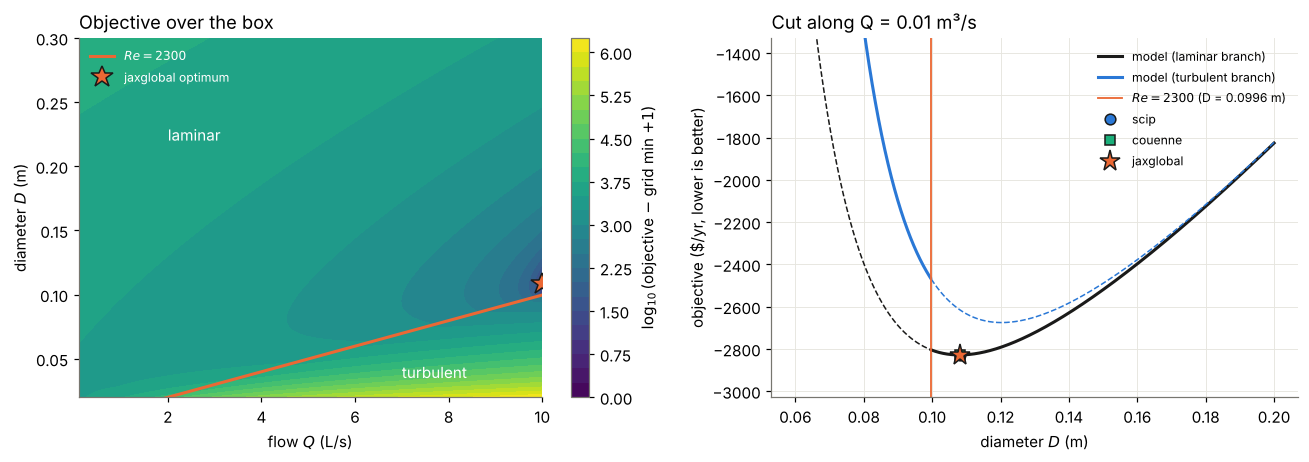

In [8]:
D_switch = 4 * RHO * QHI / (2300 * np.pi * MU)


def cost_given_f(Q, D, f):  # the objective of `pipe` with the friction factor supplied, for drawing the branches
    v = 4 * Q / (np.pi * D**2)
    eta = np.clip(0.2 + 600.0 * Q, 0.35, 0.75)
    return -PRICE * Q + E_COST * f * (LEN / D) * RHO * v**2 / 2 * Q / eta + C_PIPE * D**1.5 * LEN / 100


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
G = np.asarray(grid)
cs = ax1.contourf(np.asarray(Qg) * 1e3, np.asarray(Dg), np.log10(G - G.min() + 1), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax1, label=r"$\log_{10}$(objective $-$ grid min $+ 1$)")
Qs = np.linspace(QLO, QHI, 50)
ax1.plot(Qs * 1e3, 4 * RHO * Qs / (2300 * np.pi * MU), color=ORANGE, lw=2, label="$Re = 2300$")
ax1.set_ylim(DLO, DHI)
ax1.text(2.0, 0.22, "laminar", color="white", fontsize=10)
ax1.text(7.0, 0.035, "turbulent", color="white", fontsize=10)
ax1.plot(xj[0] * 1e3, xj[1], "*", color=ORANGE, ms=15, mec=INK, label="jaxglobal optimum")
ax1.set_xlabel("flow $Q$ (L/s)")
ax1.set_ylabel("diameter $D$ (m)")
ax1.set_title("Objective over the box", loc="left")
ax1.legend(frameon=False, fontsize=8, loc="upper left", labelcolor="white")
ax1.grid(False)

Dc = np.linspace(0.06, 0.2, 600)
Rec = 4 * RHO * QHI / (np.pi * MU * Dc)
lam_c, turb_c = cost_given_f(QHI, Dc, 64 / Rec), cost_given_f(QHI, Dc, sj(Rec, Dc))
sel = Rec < 2300
ax2.plot(Dc[sel], lam_c[sel], color=INK, lw=2, label="model (laminar branch)")
ax2.plot(Dc[~sel], turb_c[~sel], color=BLUE, lw=2, label="model (turbulent branch)")
ax2.plot(Dc[~sel], lam_c[~sel], color=INK, lw=1, ls="--")
ax2.plot(Dc[sel], turb_c[sel], color=BLUE, lw=1, ls="--")
ax2.axvline(D_switch, color=ORANGE, lw=1.2, label=f"$Re = 2300$ (D = {D_switch:.4f} m)")
for r in rows:
    if np.isfinite(r["obj"]):
        d = xj[1] if r["solver"] == "jaxglobal" else pyomo_xa[r["solver"]][1]
        ax2.plot(d, r["obj"], MARKER[r["solver"]], color=COLOR[r["solver"]], mec=INK,
                 ms=14 if r["solver"] == "jaxglobal" else 7, label=r["solver"])  # fmt: skip
ax2.set_ylim(lam_c[sel].min() - 200, lam_c[sel].min() + 1500)
ax2.set_xlabel("diameter $D$ (m)")
ax2.set_ylabel("objective (\\$/yr, lower is better)")
ax2.set_title(f"Cut along Q = {QHI} m³/s", loc="left")
ax2.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

The optimum pushes the flow to its upper bound, because each extra unit of flow earns more than it costs to pump in laminar
flow. The diameter then balances pipe cost (rising like $D^{1.5}$) against laminar pumping cost (falling like $D^{-4}$),
and that balance lands slightly to the laminar side of the switch. Just to its left the turbulent branch takes over and the
cost jumps up. Everything agrees: all solvers that ran find the same point, to within the 1e-4 tolerance.

### How jaxglobal closed the gap

Below, after each branch-and-bound iteration: how far the best point found so far (the upper bound) is above the best
objective any solver reported, and the gap between the upper bound and the lower bound over all open boxes. The search
stops when the gap is below the tolerance. Where no gap is plotted, the lower bound was still $-\infty$. The reason is the discarded branch of the `where`: on a box
that straddles the switch both branches are bounded and hulled, and interval arithmetic on $Re = \rho v D/\mu$ with
$v = 4Q/(\pi D^2)$ loses the cancellation of $D$, so the computed range of $Re$ is far wider than the true one and reaches
the pole of the Swamee-Jain formula. The next cell shows this on the root box.

In [9]:
from jaxglobal import relax


def reynolds(x):  # Re exactly as `pipe` computes it
    v = 4 * x[0] / (jnp.pi * x[1] ** 2)
    return RHO * v * x[1] / MU


lo_box, hi_box, x_mid = jnp.array([QLO, DLO]), jnp.array([QHI, DHI]), jnp.array([5e-3, 0.1])
re_root = relax(reynolds)(x_mid, lo_box, hi_box)
f_root = relax(pipe)(x_mid, lo_box, hi_box)
re_pole = (5.74 / (1 - EPS / (3.7 * DHI))) ** (1 / 0.9)
print(f"true range of Re on the box     : [{4 * RHO * QLO / (np.pi * MU * DHI):.2f}, {4 * RHO * QHI / (np.pi * MU * DLO):.0f}]")
print(f"interval range of Re, as written: [{float(re_root.lo):.2f}, {float(re_root.hi):.0f}]")
print(f"Swamee-Jain pole (D = {DHI} m) at Re = {re_pole:.2f}")
print(f"root-box interval of the objective: [{float(f_root.lo)}, {float(f_root.hi)}]")

true range of Re on the box     : [7.64, 11459]
interval range of Re, as written: [0.51, 171887]
Swamee-Jain pole (D = 0.3 m) at Re = 6.97
root-box interval of the objective: [-inf, inf]


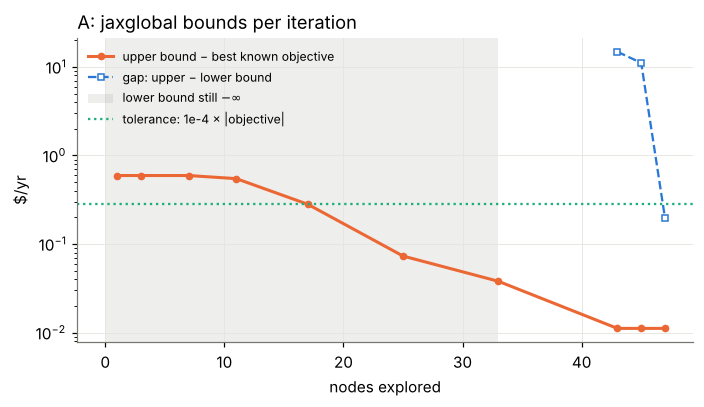

10 iterations, 47 nodes, final gap 0.196 (tolerance 0.283)


In [10]:
def plot_history(ax, res, ref, title):
    h = np.array(res.history, dtype=float)  # rows: (iteration, nodes so far, lower bound, upper bound, open boxes)
    nodes, lb, ub = h[:, 1], h[:, 2], h[:, 3]
    ax.semilogy(nodes, np.maximum(ub - ref, 1e-12 * abs(ref)), "o-", color=ORANGE, lw=2, ms=4,
                label="upper bound − best known objective")  # fmt: skip
    fin = np.isfinite(lb)
    ax.semilogy(nodes[fin], ub[fin] - lb[fin], "s--", color=BLUE, lw=1.5, ms=4, mfc="white", label="gap: upper − lower bound")
    if (~fin).any():
        ax.axvspan(0, nodes[~fin].max(), color=MUTED, alpha=0.12, lw=0, label="lower bound still $-\\infty$")
    ax.axhline(1e-4 * abs(ref), color=AQUA, lw=1.5, ls=":", label="tolerance: 1e-4 × |objective|")
    ax.set_xlabel("nodes explored")
    ax.set_title(title, loc="left")


ref_a = np.nanmin([r["obj"] for r in rows])
fig, ax = plt.subplots(figsize=(6.5, 3.8))
plot_history(ax, res_a, ref_a, "A: jaxglobal bounds per iteration")
ax.set_ylabel("\\$/yr")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
print(f"{res_a.iterations} iterations, {res_a.nodes} nodes, final gap {res_a.gap:.3g} "
      f"(tolerance {1e-4 * abs(res_a.fun):.3g})")  # fmt: skip

Read the plot from left to right. The upper bound only moves when a better point is found. The lower bound starts at
$-\infty$, as the root-box check shows it must; it becomes finite only after the boxes are split small enough that the
computed range of $Re$ stays clear of the pole, and then the gap falls below the tolerance line within a few iterations.
Pyomo avoids this particular trap because $Re$ is a variable with tight hand-made bounds, which is the
kind of reformulation a modeler adds for exactly this reason; the price is that the modeler must think of it.

## B. Steam-heated exchanger with property tables

A process stream at $T_{proc}$ = 140 °C needs $\dot Q$ = 2000 kW from condensing steam. The decision variables are the steam pressure $P$ (2 to 60 bar) and the exchanger area $A$ (5 to 400 m²).
Higher pressure means a hotter condensing temperature and so a smaller exchanger, but steam at higher pressure has a lower latent heat and a higher price.

Data, as functions of pressure: saturation temperature $T_{sat}$, latent heat $h_{fg}$, steam price.
$T_{sat}$ and $h_{fg}$ are IAPWS-IF97 saturation values [wagner2000iapws], generated with the Python package `iapws` 1.5.5
and rounded; the price column is an illustrative tiered utility cost, not a market quote.

With $T_{sat}$, $h_{fg}$ and the price $c$ read from the tables by linear interpolation, overall heat-transfer coefficient
$U$ = 0.8 kW/(m² K), 8000 operating hours a year and an annualized exchanger cost of $600\,A^{0.65}$ \$/yr, the model is

$$ \min_{P,\,A}\ \ \underbrace{\frac{\dot Q}{h_{fg}(P)}}_{\dot m\ \text{(kg/s)}} \cdot 3.6 \cdot 8000 \cdot c(P) \;+\; 600\,A^{0.65}
   \qquad \text{s.t.}\quad U A \max\big(T_{sat}(P) - T_{proc},\ 0\big) \ \ge\ \dot Q, \quad 2 \le P \le 60,\quad 5 \le A \le 400 . $$

The factor 3.6 converts kg/s to t/h. The duty constraint uses the condensing temperature difference as the driving force
(the process side is held at $T_{proc}$), and the $\max(\cdot, 0)$ says that steam colder than the process delivers nothing.
The hard parts for a global solver: the duty constraint is a product of $A$ with a table, so the feasible set
$A \ge \dot Q / (U\,(T_{sat}(P) - T_{proc}))$ is bounded by a curve with kinks; the objective is a ratio of two tables times a
third, which is nonconvex with kinks at every breakpoint.

In [11]:
P_TAB = np.array([2, 5, 10, 20, 40, 60.0])  # bar
T_TAB = np.array([120.21, 151.84, 179.89, 212.38, 250.36, 275.59])  # C, IAPWS-IF97 saturation
H_TAB = np.array([2201.6, 2107.9, 2014.4, 1889.8, 1713.5, 1570.8])  # kJ/kg, h_g - h_f
C_TAB = np.array([14, 16, 20, 26, 34, 44.0])  # $/tonne, illustrative
QREQ, TPROC, UCOEF = 2000.0, 140.0, 0.8  # kW, C, kW/m2/K

The natural Python is `jnp.interp(P, P_TAB, T_TAB)`. Does jaxglobal accept it?

In [12]:
def steam_interp(x):
    P, A = x[0], x[1]
    price, hfg = jnp.interp(P, P_TAB, C_TAB), jnp.interp(P, P_TAB, H_TAB)
    return QREQ / hfg * 3.6 * 8000 * price + 600.0 * A**0.65


try:
    solve_jax(steam_interp, [2.0, 5.0], [60.0, 400.0])
except Exception as e:  # noqa: BLE001
    print(f"{type(e).__name__}: {e}")

KeyError: 'lt_to'


**No.** `jnp.interp` lowers to a `searchsorted` (a binary search over the breakpoints), whose comparison primitive `lt_to`
has no rule in jaxglobal's primitive rule table (`RULES` in `jaxglobal/relax.py`, which the bound propagation in `fbbt.py`
also uses). This is a gap in the current prototype, not a fundamental limit: the error is raised before any search starts
and names the missing primitive. A piecewise-linear table can be written without `searchsorted`, as a sum of hinge functions,

$$ y(x) = y_0 + \sum_{i=0}^{n-1} \Delta s_i\, \max(x - x_i,\ 0), \qquad
   \Delta s_0 = s_0,\quad \Delta s_i = s_i - s_{i-1},\quad s_i = \frac{y_{i+1} - y_i}{x_{i+1} - x_i}, $$

where $s_i$ is the slope of segment $i$ and $\Delta s_i$ the change in slope at breakpoint $x_i$. On $[x_0, x_n]$ this equals
the linear interpolant: at $x$ in segment $k$ the active hinges add up to $y_k + s_k(x - x_k)$. Each $\max$ is a primitive
that jaxglobal relaxes directly, so this is exactly the kind of small helper you write once. The rest of this case uses it.

In [13]:
def pwl(x, xs, ys):
    """Piecewise-linear interpolation as a sum of hinge functions (constant below xs[0], linear beyond xs[-1])."""
    s = np.diff(ys) / np.diff(xs)
    dk = np.concatenate([[s[0]], np.diff(s)])
    return ys[0] + sum(float(k) * jnp.maximum(x - float(xi), 0.0) for k, xi in zip(dk, xs[:-1]))


def steam(x):
    P, A = x[0], x[1]
    mdot = QREQ / pwl(P, P_TAB, H_TAB)  # kg/s
    return mdot * 3.6 * 8000 * pwl(P, P_TAB, C_TAB) + 600.0 * A**0.65  # steam $/yr + exchanger $/yr


def steam_ineq(x):
    P, A = x[0], x[1]
    return QREQ - UCOEF * A * jnp.maximum(pwl(P, P_TAB, T_TAB) - TPROC, 0.0)  # delivered duty >= required

The three tables and their hinge-sum interpolants, with `jnp.interp` evaluated (as plain JAX, outside the solver) on top
as a check. $T_{sat}(P)$ is concave, so its chords lie below the true curve between table points: the interpolant
slightly underestimates the driving temperature difference.

saturation temperature $T_{sat}$: max |pwl - interp| = 1.14e-13
            latent heat $h_{fg}$: max |pwl - interp| = 4.55e-13
                 steam price $c$: max |pwl - interp| = 1.42e-14


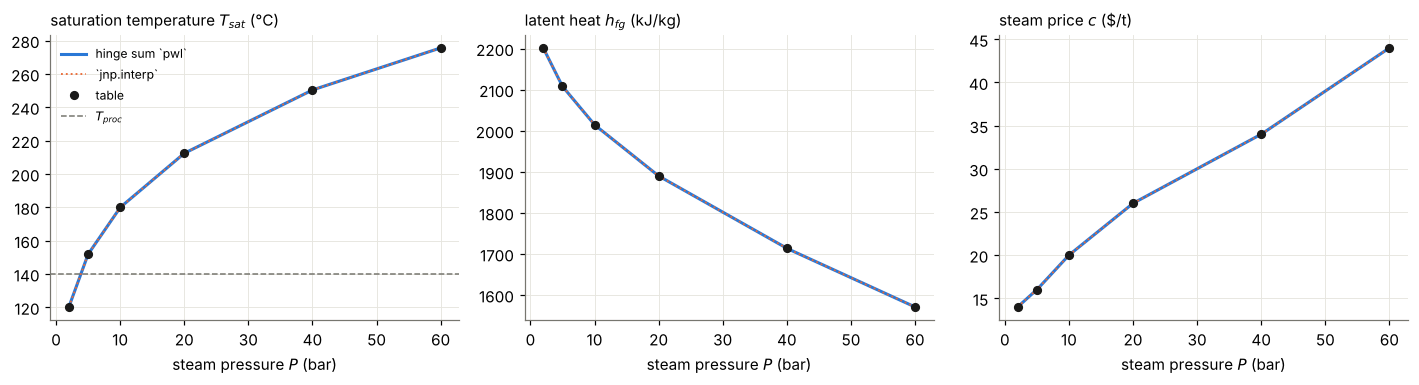

In [14]:
Pp = np.linspace(2, 60, 600)
tabs = [(T_TAB, "saturation temperature $T_{sat}$ (°C)"), (H_TAB, "latent heat $h_{fg}$ (kJ/kg)"),
        (C_TAB, "steam price $c$ (\\$/t)")]  # fmt: skip
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (tab, lab) in zip(axes, tabs):
    yh = np.asarray(jax.vmap(lambda p, tab=tab: pwl(p, P_TAB, tab))(jnp.asarray(Pp)))
    yi = np.asarray(jnp.interp(jnp.asarray(Pp), P_TAB, tab))
    ax.plot(Pp, yh, color=BLUE, lw=2, label="hinge sum `pwl`")
    ax.plot(Pp, yi, color=ORANGE, lw=1.2, ls=":", label="`jnp.interp`")
    ax.plot(P_TAB, tab, "o", color=INK, ms=5, label="table")
    ax.set_xlabel("steam pressure $P$ (bar)")
    ax.set_title(lab, loc="left", fontsize=10)
    print(f"{lab.split(' (')[0]:>32}: max |pwl - interp| = {np.abs(yh - yi).max():.2e}")
axes[0].axhline(TPROC, color=MUTED, lw=1, ls="--", label="$T_{proc}$")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### Pyomo

Three tables of the same variable, so three `Piecewise` blocks. Six breakpoints give five segments and, in the
incremental formulation above, four binaries per table. The `max(0, T_sat - T_proc)` is not needed as a function: since the required duty is positive,
any feasible point has $T_{sat} > T_{proc}$, so the max can be replaced by requiring the duty inequality with the plain difference,

$$ U A\,\big(T_{sat} - T_{proc}\big) \ge \dot Q . $$

That is a valid simplification, but the modeler has to see it. Written literally, the max would be another disjunction.
Division by $h_{fg}$ is turned into a bilinear equation $\dot m\, h_{fg} = \dot Q$ with $\dot m$ a new variable.

In [15]:
def steam_pyomo():
    m = pyo.ConcreteModel()
    m.P = pyo.Var(bounds=(2, 60), initialize=10)
    m.A = pyo.Var(bounds=(5, 400), initialize=100)
    m.Tsat = pyo.Var(bounds=(T_TAB[0], T_TAB[-1]))
    m.hfg = pyo.Var(bounds=(H_TAB[-1], H_TAB[0]))
    m.price = pyo.Var(bounds=(C_TAB[0], C_TAB[-1]))
    m.mdot = pyo.Var(bounds=(QREQ / H_TAB[0], QREQ / H_TAB[-1]))
    for name, tab in [("Tsat", T_TAB), ("hfg", H_TAB), ("price", C_TAB)]:
        setattr(m, name + "_pw", pyo.Piecewise(
            getattr(m, name), m.P, pw_pts=list(P_TAB), f_rule=list(tab), pw_constr_type="EQ", pw_repn="INC"))  # fmt: skip
    m.steam_flow = pyo.Constraint(expr=m.mdot * m.hfg == QREQ)
    m.duty = pyo.Constraint(expr=UCOEF * m.A * (m.Tsat - TPROC) >= QREQ)
    m.obj = pyo.Objective(expr=m.mdot * 3.6 * 8000 * m.price + 600.0 * m.A**0.65)
    return m

In [16]:
m = steam_pyomo()
size_b = model_size(m)
print(f"Pyomo: {size_b[0]} variables ({n_binary(m)} binary), {size_b[1]} constraints")
models_b = {s: steam_pyomo() for s in SOLVERS}
rows_b = [solve_pyomo(models_b[s], s) for s in SOLVERS]
rows_b.append(solve_jax(steam, [2.0, 5.0], [60.0, 400.0], ineq=steam_ineq))
res_b = JAX_RESULTS[-1]
table(rows_b)

Pyomo: 33 variables (12 binary), 32 constraints


,solver,obj,bound,time,status
0,scip,453289.727915,453249.380891,0.34,optimal
1,couenne,453289.707526,NaN,0.74,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,453289.728065,453247.390772,1.47,optimal


In [17]:
lp, lj = loc(steam_pyomo), loc(pwl, steam, steam_ineq)
save_results("09", "B: steam tables (interp, max)", lp, lj, size_b, rows_b, note=f"{n_binary(m)} binaries from Piecewise")
print(f"lines of model code: Pyomo {lp}, jaxglobal {lj} (including the pwl helper)")
print("jaxglobal optimum: P = %.2f bar, A = %.1f m2" % tuple(rows_b[-1]["x"]))
pyomo_xb = {s: (pyo.value(models_b[s].P), pyo.value(models_b[s].A)) for s, r in zip(SOLVERS, rows_b) if np.isfinite(r["obj"])}
for s, (p, a) in pyomo_xb.items():
    print(f"{s:>9}: P = {p:.2f} bar, A = {a:.1f} m2")
loc_b, bin_b = (lp, lj), n_binary(m)

lines of model code: Pyomo 15, jaxglobal 11 (including the pwl helper)
jaxglobal optimum: P = 4.58 bar, A = 337.3 m2
     scip: P = 4.58 bar, A = 337.2 m2
  couenne: P = 4.58 bar, A = 337.9 m2


### The feasible region and the optimum

Left: the annual cost over $(P, A)$, with the infeasible part (duty not met) greyed out. The boundary is
$A_{min}(P) = \dot Q / (U\,(T_{sat}(P) - T_{proc}))$, which has a vertical asymptote at the pressure where $T_{sat} = T_{proc}$.
Since the cost increases with $A$, the optimum lies on this boundary, and the problem reduces to a one-dimensional
search along it. Right: the cost along the boundary, with the table pressures marked. Its kinks are the breakpoints.

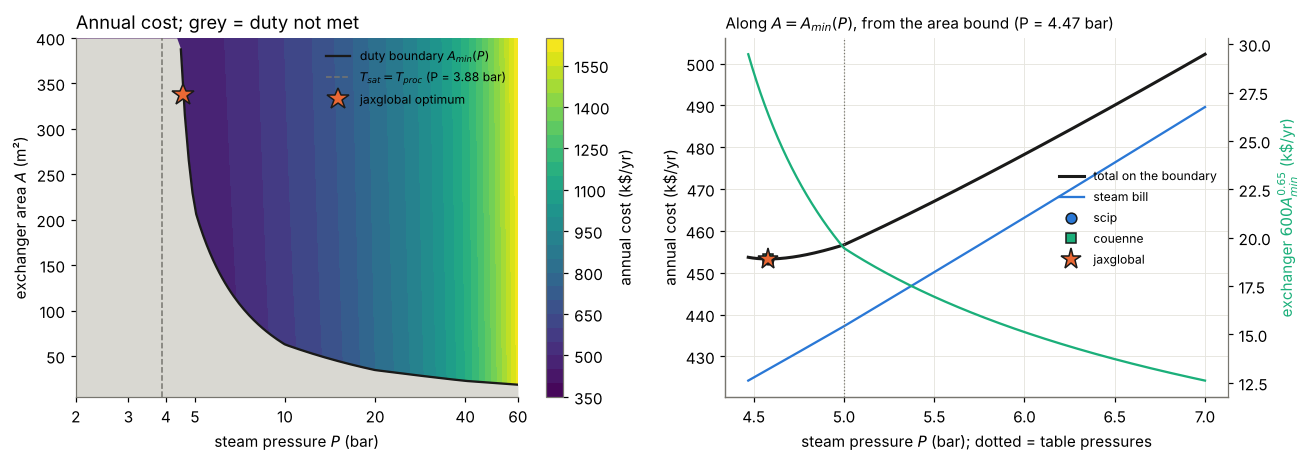

at the jaxglobal optimum: steam 426,907 $/yr, exchanger 26,383 $/yr; lowest pressure that fits A <= 400 m2: 4.47 bar


In [18]:
pg, ag = np.linspace(2, 60, 300), np.linspace(5, 400, 300)
PG, AG = np.meshgrid(pg, ag)
XB = jnp.asarray(np.stack([PG.ravel(), AG.ravel()], 1))
cost_b = np.asarray(jax.vmap(steam)(XB)).reshape(PG.shape)
infeas = np.asarray(jax.vmap(steam_ineq)(XB)).reshape(PG.shape) > 0
P_min = float(np.interp(TPROC, T_TAB, P_TAB))  # T_sat is increasing, so invert the table


def a_min(P):
    return QREQ / (UCOEF * (np.interp(P, P_TAB, T_TAB) - TPROC))


P_ticks = [2, 3, 4, 5, 10, 20, 40, 60]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
cs = ax1.contourf(PG, AG, cost_b / 1e3, levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax1, label="annual cost (k\\$/yr)")
pb = np.linspace(P_min + 0.05, 60, 400)
ab = a_min(pb)
ok = ab <= 400
ax1.fill_between(np.r_[2.0, P_min, pb], 5, np.r_[400, 400, np.minimum(ab, 400)], color="#d9d8d2", lw=0, zorder=2)
ax1.plot(pb[ok], ab[ok], color=INK, lw=1.5, zorder=3, label="duty boundary $A_{min}(P)$")
ax1.axvline(P_min, color=MUTED, lw=1, ls="--", label=f"$T_{{sat}} = T_{{proc}}$ (P = {P_min:.2f} bar)")
xb = rows_b[-1]["x"]
ax1.plot(*xb, "*", color=ORANGE, ms=15, mec=INK, zorder=4, label="jaxglobal optimum")
ax1.set_xscale("log")
ax1.set_xticks(P_ticks, [str(t) for t in P_ticks])
ax1.minorticks_off()
ax1.set_xlabel("steam pressure $P$ (bar)")
ax1.set_ylabel("exchanger area $A$ (m²)")
ax1.set_title("Annual cost; grey = duty not met", loc="left")
ax1.legend(frameon=False, fontsize=8, loc="upper right")
ax1.grid(False)

P_400 = float(np.interp(TPROC + QREQ / (UCOEF * 400), T_TAB, P_TAB))  # where A_min(P) = 400 m2, the area bound
pb2 = np.linspace(P_400, 7, 1000)
ab2 = a_min(pb2)
cb = np.asarray(jax.vmap(steam)(jnp.asarray(np.stack([pb2, ab2], 1))))
hx = 600.0 * ab2**0.65
ax2.plot(pb2, cb / 1e3, color=INK, lw=2, label="total on the boundary")
ax2.plot(pb2, (cb - hx) / 1e3, color=BLUE, lw=1.5, label="steam bill")
ax2b = ax2.twinx()
ax2b.plot(pb2, hx / 1e3, color=AQUA, lw=1.5)
ax2b.set_ylabel("exchanger $600A_{min}^{0.65}$ (k\\$/yr)", color=AQUA)
ax2b.spines["right"].set_visible(True)
ax2b.grid(False)
for p in P_TAB[(P_TAB > pb2[0]) & (P_TAB < pb2[-1])]:
    ax2.axvline(p, color=MUTED, lw=0.8, ls=":")
for r in rows_b:
    if np.isfinite(r["obj"]):
        p = xb[0] if r["solver"] == "jaxglobal" else pyomo_xb[r["solver"]][0]
        ax2.plot(p, r["obj"] / 1e3, MARKER[r["solver"]], color=COLOR[r["solver"]], mec=INK,
                 ms=14 if r["solver"] == "jaxglobal" else 7, label=r["solver"])  # fmt: skip
ax2.set_xlabel("steam pressure $P$ (bar); dotted = table pressures")
ax2.set_ylabel("annual cost (k\\$/yr)")
ax2.set_title(f"Along $A = A_{{min}}(P)$, from the area bound (P = {P_400:.2f} bar)", loc="left", fontsize=10)
ax2.legend(frameon=False, fontsize=8, loc="center right")
fig.tight_layout()
plt.show()
hx_opt = 600.0 * xb[1] ** 0.65
print(f"at the jaxglobal optimum: steam {rows_b[-1]['obj'] - hx_opt:,.0f} $/yr, exchanger {hx_opt:,.0f} $/yr; "
      f"lowest pressure that fits A <= 400 m2: {P_400:.2f} bar")  # fmt: skip

Near the asymptote the area, and so the exchanger cost, blows up; at higher pressure the steam bill dominates. The
minimum is in between, on the duty boundary and close to the low-pressure end: in this example steam is the larger cost,
so the design runs at nearly the lowest pressure that still fits the area bound. Because each table is linear between
breakpoints, the cost along the boundary is smooth inside a segment and has a kink at each table pressure (dotted lines);
the optimum here is inside a segment, not at a kink.
Again all solvers agree to the tolerance.

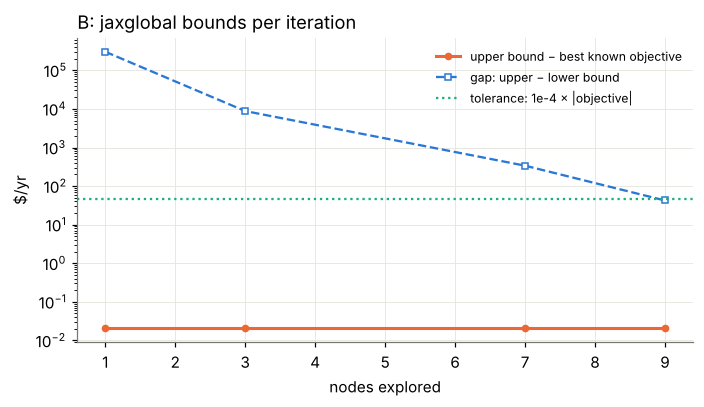

4 iterations, 9 nodes, final gap 42.3 (tolerance 45.3)


In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
plot_history(ax, res_b, np.nanmin([r["obj"] for r in rows_b]), "B: jaxglobal bounds per iteration")
ax.set_ylabel("\\$/yr")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
print(f"{res_b.iterations} iterations, {res_b.nodes} nodes, final gap {res_b.gap:.3g} "
      f"(tolerance {1e-4 * abs(res_b.fun):.3g})")  # fmt: skip

## What it cost

Wall time for each solver (log scale; a missing bar is a solver that did not run), lines of model code, and binary
variables in the model each solver receives. jaxglobal's model has no binaries: the switches stay inside the function.

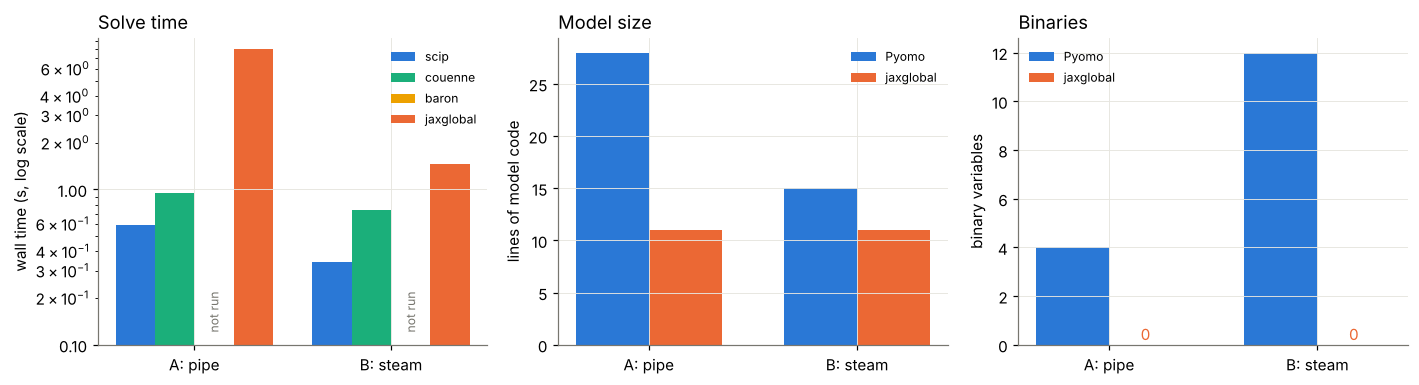

A scip 0.59 s  couenne 0.94 s  jaxglobal 8.07 s
B scip 0.34 s  couenne 0.74 s  jaxglobal 1.47 s


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
names = [*SOLVERS, "jaxglobal"]
w = 0.8 / len(names)
for k, s in enumerate(names):
    t = [r["time"] if np.isfinite(r["obj"]) else np.nan for rr in (rows, rows_b) for r in rr if r["solver"] == s]
    xpos = np.arange(2) + (k - (len(names) - 1) / 2) * w
    axes[0].bar(xpos, t, w, color=COLOR[s], label=s)
    for xp, tt in zip(xpos, t):
        if not np.isfinite(tt):
            axes[0].text(xp, 0.12, "not run", rotation=90, ha="center", va="bottom", fontsize=8, color=MUTED)
axes[0].set_yscale("log")
axes[0].set_ylabel("wall time (s, log scale)")
axes[0].yaxis.set_major_formatter(plt.ScalarFormatter())
axes[0].set_ylim(0.1, None)
for ax in axes:
    ax.set_xticks([0, 1], ["A: pipe", "B: steam"])
for k, (lab, vals, c) in enumerate([("Pyomo", [loc_a[0], loc_b[0]], BLUE), ("jaxglobal", [loc_a[1], loc_b[1]], ORANGE)]):
    axes[1].bar(np.arange(2) + (k - 0.5) * 0.35, vals, 0.35, color=c, label=lab)
axes[1].set_ylabel("lines of model code")
axes[2].bar(np.arange(2) - 0.175, [bin_a, bin_b], 0.35, color=BLUE, label="Pyomo")
axes[2].bar(np.arange(2) + 0.175, [0, 0], 0.35, color=ORANGE, label="jaxglobal")
axes[2].set_ylabel("binary variables")
for i in range(2):
    axes[2].text(i + 0.175, 0.2, "0", ha="center", color=ORANGE)
for ax, title in zip(axes, ["Solve time", "Model size", "Binaries"]):
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
for rr, case in ((rows, "A"), (rows_b, "B")):
    print(case, "  ".join(f"{r['solver']} {r['time']:.2f} s" for r in rr if np.isfinite(r["obj"])))

## What was hard

**In Pyomo**

* **Every switch is a MIP construct.** The `where` became a two-disjunct `Disjunction` plus a big-M transformation, with 4 binary variables in total once the piecewise efficiency curve is included. The tables became 12 binaries. Pyomo does this for you, but only after you restate the model on variables with defining equations.
* **Bounds are your job.** Big-M needs finite bounds on `Re` and `f`, derived by hand here. Loose bounds weaken the relaxation; missing bounds make the transformation fail.
* **Reformulation judgment.** Division became a bilinear equation, and `max(0, dT)` could be dropped only because of an argument about feasibility. Neither is hard once seen, but they are the kind of step that makes algebraic models error-prone when copied from code.
* **The model no longer reads like the physics.** The jaxglobal code can be compared to a textbook line by line; the Pyomo model has to be read together with its transformation.

**In jaxglobal**

* `where`, `clip` and `maximum` are traced as ordinary primitives; no auxiliary variables, no bounds on intermediates, no binaries.
* `jnp.interp` is **not supported yet** (no rule for the `lt_to` comparison inside its `searchsorted`). The hinge-sum workaround above works but is something the user must know about.
* jaxglobal is slower here: compare the times printed above. Its wall time includes tracing and compiling the bounding
  kernels on the first call (notebook 05 measures that cost separately), and the machine these notebooks run on is shared,
  so only large ratios mean anything. Branch-and-bound over a discontinuous function (`where`) relies on interval tests and is not tuned.
* The discontinuous friction switch is handled by hulling the two branches in boxes that straddle $Re=2300$. Because both
  branches are bounded on such boxes, a branch that is never selected can still spoil the bound, as the Swamee-Jain pole
  did in case A until those boxes were split away. The optimum here is not on the switch, so this costs nodes but not correctness. If the optimum sat exactly on a discontinuity, the infimum might not be attained and all tools (not only jaxglobal) would struggle.

**Where Pyomo is better, even here:** the solvers are faster and give no-surprise status codes; the GDP blocks are named, so you can inspect which disjunct is active; the same model can be sent to a MILP/MINLP solver of your choice; and the whole thing extends to integer decisions (for example, a choice among standard pipe diameters), which jaxglobal could pose with `integer=` but which these notebooks do not try.